# Análise exploratória — Computação e TIC (2019–2024)

Dados reais do ETL; validação externa integral pendente.

## 0. Configuração

In [1]:
from pathlib import Path
import sys
print("Python:", sys.version.split()[0])
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import plotly.io as pio
pio.renderers.default = "plotly_mimetype"
from src import contract, analysis, viz, synthetic
MODO = 'real'
PARQUET = ROOT / 'data/processed/agregado_anual.parquet'
META = ROOT / 'data/processed/agregado_anual.meta.json'

Python: 3.12.14


In [2]:
if MODO == 'sintetico':
    df, meta = synthetic.gerar()
    print('ATENÇÃO: DADOS SINTÉTICOS — APENAS TESTE')
else:
    df, meta = contract.carregar(PARQUET, META)
SINT = df.attrs['origem'] == 'SINTETICO'
print('avisos do contrato:', contract.validar(df, meta))
assert set(df.ano) == set(range(2019, 2025))
assert len(df) == 24
if not SINT:
    import hashlib
    manifest = ROOT / meta["fonte_manifest"]["path"]
    assert hashlib.sha256(manifest.read_bytes()).hexdigest() == meta["fonte_manifest"]["sha256"], "Manifesto divergente"
    print("Manifesto SHA-256 conferido; reconciliação externa integral pendente.")


avisos do contrato: []
Manifesto SHA-256 conferido; reconciliação externa integral pendente.


## 1. Estrutura e qualidade dos dados agregados

In [3]:
display(df.head(8))
df.info()
df.groupby(['escopo', 'modalidade']).size().unstack()

,ano,escopo,modalidade,qt_mat,qt_mat_fem,qt_mat_masc,qt_ing
0,2019,total_graduacao,presencial,6153560,3430115,2723445,2041136
1,2019,total_graduacao,ead,2448405,1506843,941562,1590784
2,2019,computacao_tic,presencial,251563,33835,217728,104823
3,2019,computacao_tic,ead,102346,14033,88313,78894
4,2020,total_graduacao,presencial,5574551,3149703,2424848,1756496
5,2020,total_graduacao,ead,3103449,1870775,1232674,2007257
6,2020,computacao_tic,presencial,239875,34205,205670,99433
7,2020,computacao_tic,ead,159410,24689,134721,127567


<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ano          24 non-null     int64
 1   escopo       24 non-null     str  
 2   modalidade   24 non-null     str  
 3   qt_mat       24 non-null     int64
 4   qt_mat_fem   24 non-null     int64
 5   qt_mat_masc  24 non-null     int64
 6   qt_ing       24 non-null     int64
dtypes: int64(5), str(2)
memory usage: 1.9 KB


modalidade,ead,presencial
escopo,,
computacao_tic,6,6
total_graduacao,6,6


In [4]:
df.groupby('escopo')[contract.METRICAS].apply(lambda g: g.apply(analysis.resumo_descritivo)).round(2)

qt_mat  qt_mat_fem  qt_mat_masc      qt_ing
escopo                                                                    
computacao_tic  count           12.00       12.00        12.00       12.00
                mean        277911.33    48135.75    229775.58   171188.25
                std         104884.85    24931.49     80547.72    98026.09
                min         102346.00    14033.00     88313.00    78894.00
                25%         232462.75    34112.50    195958.50   103475.50
                50%         255328.50    40515.00    218041.50   133048.00
                75%         320725.75    56943.00    263782.75   215617.75
                max         483835.00    99762.00    384073.00   350278.00
                amplitude   381489.00    85729.00    295760.00   271384.00
                cv               0.38        0.52         0.35        0.57
total_graduacao count           12.00       12.00        12.00       12.00
                mean       4658577.00  2729533.33   1929043.67  2174619.17
                std        1070671.07   570795.00    508817.31   703871.98
                min        2448405.00  1506843.00    941562.00  1467523.00
                25%        4174498.50  2528425.00   1646073.50  1661188.00
                50%        5050491.50  2942660.00   2068819.00  1881876.50
                75%        5207685.00  3039976.50   2196527.75  2631704.00
                max        6153560.00  3430115.00   2723445.00  3346116.00
                amplitude  3705155.00  1923272.00   1781883.00  1878593.00
                cv               0.23        0.21         0.26        0.32

## 2. RQ1 — Matrículas em Computação e TIC: absolutas e proporcionais ao total da graduação

In [5]:
r1 = analysis.rq1(df); display(r1.round(2))
print('CAGR matrículas Computação/TIC:', analysis.cagr(r1.mat_computacao.iloc[0], r1.mat_computacao.iloc[-1], len(r1) - 1))
viz.plotly_rq1(r1, SINT).show()

,ano,mat_computacao,mat_total_graduacao,participacao_pct,delta_participacao_pp,var_pct_mat_computacao,indice_mat_computacao,var_pct_mat_total_graduacao,indice_mat_total_graduacao
0,2019,353909,8601965,4.11,NaN,NaN,100.00,NaN,100.00
1,2020,399285,8678000,4.60,0.49,12.82,112.82,0.88,100.88
2,2021,463823,8983830,5.16,0.56,16.16,131.06,3.52,104.44
3,2022,594102,9440779,6.29,1.13,28.09,167.87,5.09,109.75
4,2023,724017,9974016,7.26,0.97,21.87,204.58,5.65,115.95
5,2024,799800,10224334,7.82,0.56,10.47,225.99,2.51,118.86


CAGR matrículas Computação/TIC: 0.1771124646817015


**Interpretação:** As matrículas cresceram 126,0%, contra 18,86% no total da graduação, e a participação da área aumentou 3,71 p.p. O crescimento anual mais forte foi em 2022 (28,09%); a taxa composta anual foi de aproximadamente 17,7%. Isso indica expansão relativa da área, sem demonstrar suas causas.

## 3. RQ2 — Participação do EaD em matrículas e ingressantes

In [6]:
r2 = analysis.rq2(df); display(r2.round(2))
viz.plotly_rq2(r2, SINT).show()

,ano,escopo,indicador,qt_ead,qt_total,pct_ead,delta_pp
0,2019,computacao_tic,matriculas,102346,353909,28.92,NaN
1,2020,computacao_tic,matriculas,159410,399285,39.92,11.01
2,2021,computacao_tic,matriculas,230809,463823,49.76,9.84
3,2022,computacao_tic,matriculas,335008,594102,56.39,6.63
4,2023,computacao_tic,matriculas,425870,724017,58.82,2.43
5,2024,computacao_tic,matriculas,483835,799800,60.49,1.67
6,2019,computacao_tic,ingressantes,78894,183717,42.94,NaN
7,2020,computacao_tic,ingressantes,127567,227000,56.20,13.25
8,2021,computacao_tic,ingressantes,190904,272074,70.17,13.97
9,2022,computacao_tic,ingressantes,289759,410127,70.65,0.48


**Interpretação:** O EaD passou de 28,92% a 60,49% das matrículas (+31,58 p.p.) e de 42,94% a 71,66% dos ingressantes (+28,72 p.p.). A modalidade tornou-se majoritária entre ingressantes em 2020 e entre matrículas em 2022. A ampliação da oferta remota é compatível com a expansão observada, mas não permite atribuí-la à pandemia ou a políticas específicas.

## 4. RQ3 — Participação feminina por modalidade

In [7]:
r3 = analysis.rq3(df); display(r3.round(2))
viz.plotly_rq3(r3, SINT).show()

,ano,modalidade,qt_mat_fem,qt_mat_masc,escopo,pct_fem,delta_pp
0,2019,ead,14033,88313,computacao_tic,13.71,NaN
1,2020,ead,24689,134721,computacao_tic,15.49,1.78
2,2021,ead,40291,190518,computacao_tic,17.46,1.97
3,2022,ead,65757,269251,computacao_tic,19.63,2.17
4,2023,ead,85983,339887,computacao_tic,20.19,0.56
5,2024,ead,99762,384073,computacao_tic,20.62,0.43
6,2019,presencial,33835,217728,computacao_tic,13.45,NaN
7,2020,presencial,34205,205670,computacao_tic,14.26,0.81
8,2021,presencial,35242,197772,computacao_tic,15.12,0.86
9,2022,presencial,40739,218355,computacao_tic,15.72,0.60


**Interpretação:** A participação feminina total avançou de 13,53% a 19,23% (+5,70 p.p.). Em 2024, alcançou 17,09% no presencial e 20,62% no EaD. A diferença entre modalidades não demonstra que o EaD cause maior inclusão: composição dos cursos, perfis e condições de acesso podem contribuir. A maioria das matrículas ainda é masculina.

In [8]:
# Dispersão, identificação exploratória de outliers (IQR) e correlação
s = r1.set_index('ano').mat_computacao
display(analysis.resumo_descritivo(s))
q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
print('Outliers IQR:', s[(s < q1-1.5*iqr) | (s > q3+1.5*iqr)].to_dict())
p = r2.pivot(index='ano',columns='indicador',values='pct_ead')
display(p.corr())
# Seis anos, séries temporais: correlação descritiva, não causal.

count             6.000000
mean         555822.666667
std          180563.943713
min          353909.000000
25%          415419.500000
50%          528962.500000
75%          691538.250000
max          799800.000000
amplitude    445891.000000
cv                0.324859
Name: mat_computacao, dtype: float64

Outliers IQR: {}


indicador,ingressantes,matriculas
indicador,,
ingressantes,1.000000,0.962679
matriculas,0.962679,1.000000


## 5. Exportação das figuras

Figuras sintéticas vão para `_sintetico/` (nunca para `docs/`); as oficiais, para `docs/assets/`.

figuras em C:\Users\alessandro.davi\Documents\Codex\2026-11-19\dei\work\censo-superior-tic\docs\assets


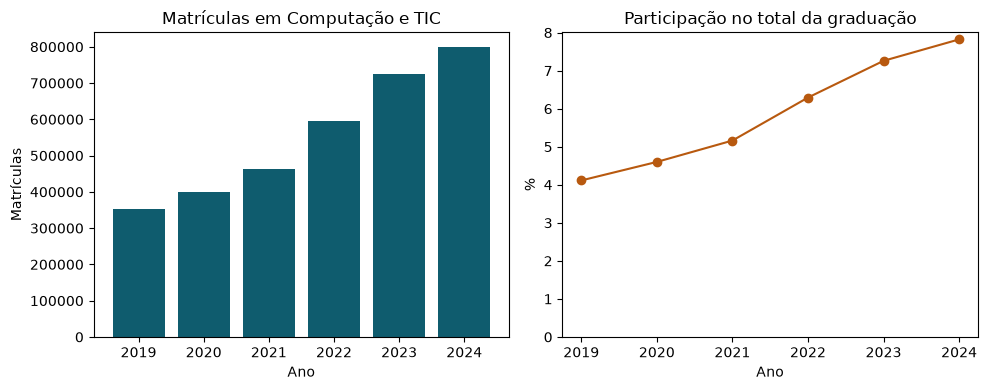

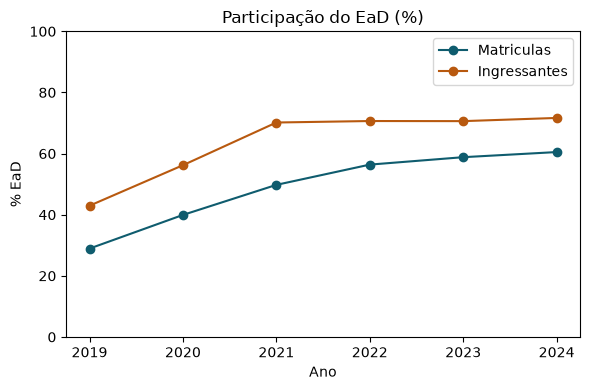

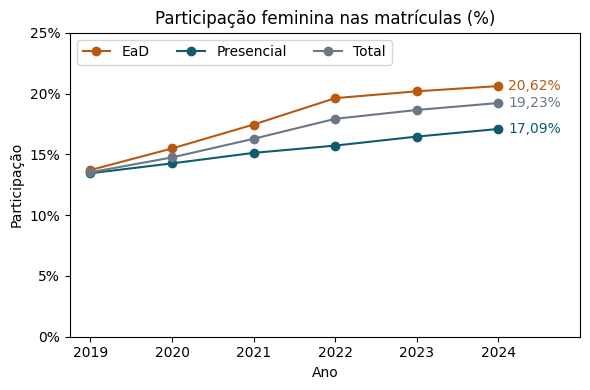

In [9]:
pasta = ROOT / ('_sintetico' if SINT else 'docs/assets')
for nome, r, pf, mf in [('fig_rq1', r1, viz.plotly_rq1, viz.mpl_rq1), ('fig_rq2', r2, viz.plotly_rq2, viz.mpl_rq2), ('fig_rq3', r3, viz.plotly_rq3, viz.mpl_rq3)]:
    viz.salvar(nome, pf(r, SINT), mf(r, SINT), pasta, SINT)
print('figuras em', pasta)
if not SINT:
    for i, tabela in enumerate([r1, r2, r3], 1):
        tabela.to_csv(f'{pasta}/rq{i}.csv', index=False)